In [43]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import preprocessing

from keras.layers import Dense, BatchNormalization, Dropout, LSTM
from keras.models import Sequential
from keras.utils import to_categorical
from keras.optimizers import Adam
from keras import callbacks

from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

np.random.seed(0)

# <h1 style='background:#C2C4E2; border:0; color:black'><center>RAIN PREDICTION</center></h1>

![Rain Prediction Banner](attachment:Memphis%20Stop%20Start%20Continue%20Brainstorm%20Presentation%20%281%29.png)

<a id="top"></a>

# <h1 style='background:#C2C4E2; border:0; color:black'><center>TABLE OF CONTENTS</center></h1>

1. [Importing Libraries](#1)
2. [Loading Data](#2)
3. [Data Visualization and Cleaning](#3)
4. [Data Preprocessing](#4)
5. [Model Building](#5)
6. [Conclusion](#6)
7. [End](#7)

<a id="1"></a>

# <h1 style='background:#C2C4E2; border:0; color:black'><center>1. IMPORTING LIBRARIES</center></h1>

Import the Python libraries required for data analysis, visualization, preprocessing, and model building.


# <a id="2"></a>

<h1 style='background:#C2C4E2; border:0; color:black'><center>2. LOADING DATA</center></h1>

In this section, we load the rain prediction dataset using Pandas and inspect its structure.




In [44]:
import pandas as pd

# Load the dataset
df = pd.read_csv("weatherAUS.csv")

# Display the first five rows
df.head()


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [45]:
# Check data types and missing values
df.info()

# Count missing values in each column
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

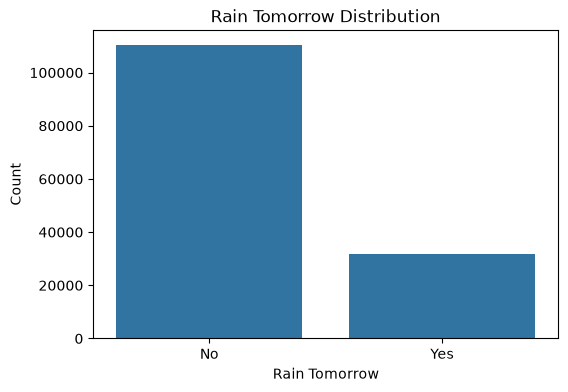

In [46]:
# Plot the target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="RainTomorrow")
plt.title("Rain Tomorrow Distribution")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Count")
plt.show()

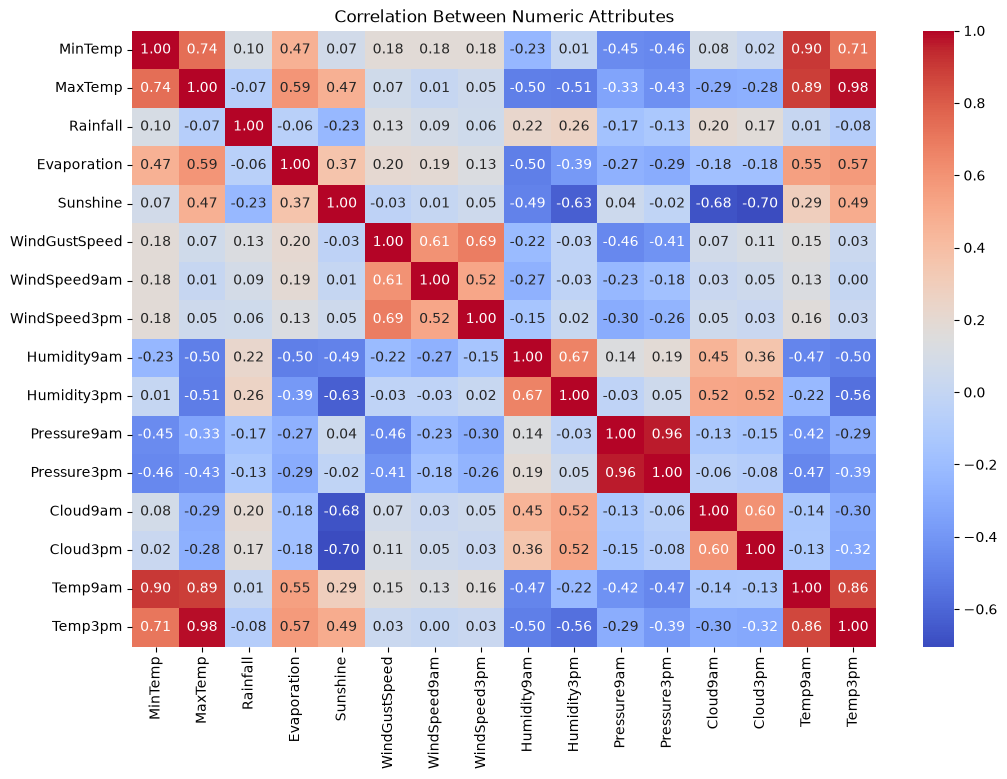

In [47]:
# Select numeric columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation matrix
corr = numeric_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numeric Attributes")
plt.show()

In [48]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Extract year, month, and day
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

df[["Date", "Year", "Month", "Day"]].head()

,Date,Year,Month,Day
0,2008-12-01,2008,12,1
1,2008-12-02,2008,12,2
2,2008-12-03,2008,12,3
3,2008-12-04,2008,12,4
4,2008-12-05,2008,12,5


In [49]:
import pandas as pd
import numpy as np

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Extract year, month and day
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day

# Function to create cyclic features
def encode(df, col, max_val):
    df[col + '_sin'] = np.sin(2 * np.pi * df[col] / max_val)
    df[col + '_cos'] = np.cos(2 * np.pi * df[col] / max_val)
    return df

# Encode month
df = encode(df, 'month', 12)

# Encode day
df = encode(df, 'day', 31)

# Display the new features
df[['Date', 'year', 'month', 'month_sin', 'month_cos',
    'day', 'day_sin', 'day_cos']].head()

,Date,year,month,month_sin,month_cos,day,day_sin,day_cos
0,2008-12-01,2008,12,-2.449294e-16,1.0,1,0.201299,0.979530
1,2008-12-02,2008,12,-2.449294e-16,1.0,2,0.394356,0.918958
2,2008-12-03,2008,12,-2.449294e-16,1.0,3,0.571268,0.820763
3,2008-12-04,2008,12,-2.449294e-16,1.0,4,0.724793,0.688967
4,2008-12-05,2008,12,-2.449294e-16,1.0,5,0.848644,0.528964


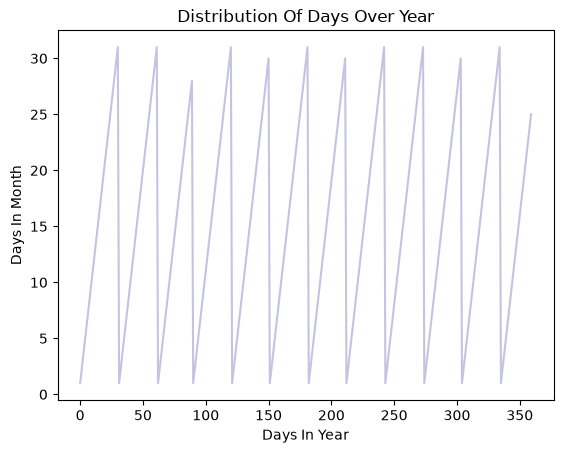

In [50]:
# Select approximately one year's data
section = df[:360]

# Plot day distribution
tm = section["day"].plot(color="#C2C4E2")

# Add title and labels
tm.set_title("Distribution Of Days Over Year")
tm.set_ylabel("Days In Month")
tm.set_xlabel("Days In Year")

plt.show()

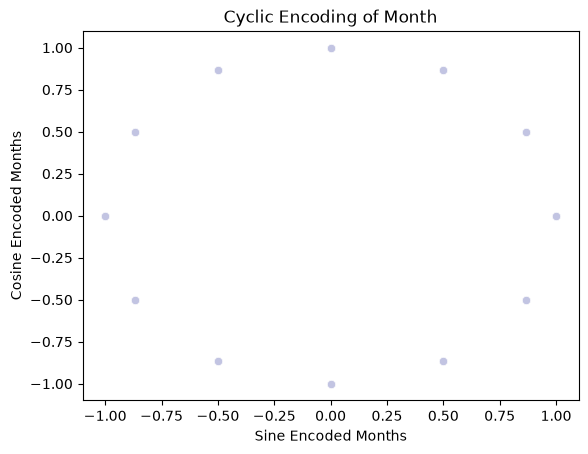

In [51]:
# Plot cyclic month encoding
cyclic_month = sns.scatterplot(
    x="month_sin",
    y="month_cos",
    data=df,
    color="#C2C4E2"
)

# Add title and axis labels
cyclic_month.set_title("Cyclic Encoding of Month")
cyclic_month.set_ylabel("Cosine Encoded Months")
cyclic_month.set_xlabel("Sine Encoded Months")

plt.show()

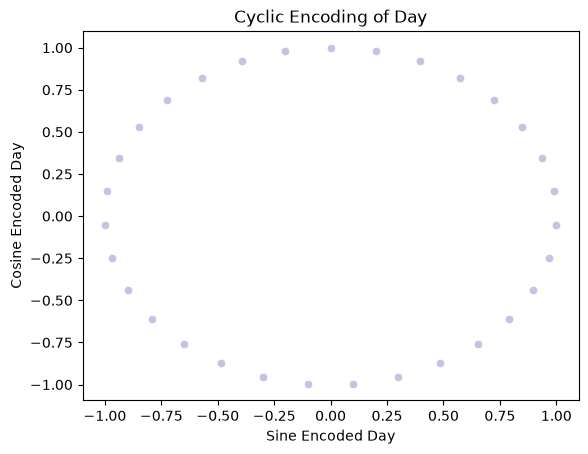

In [52]:
# Plot cyclic day encoding
cyclic_day = sns.scatterplot(
    x='day_sin',
    y='day_cos',
    data=df,
    color="#C2C4E2"
)

# Add title and axis labels
cyclic_day.set_title("Cyclic Encoding of Day")
cyclic_day.set_ylabel("Cosine Encoded Day")
cyclic_day.set_xlabel("Sine Encoded Day")

plt.show()

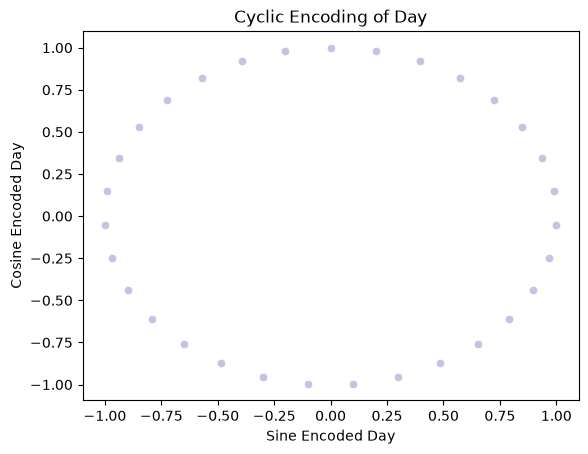

In [53]:
# Plot cyclic encoding of day
cyclic_day = sns.scatterplot(
    x='day_sin',
    y='day_cos',
    data=df,
    color="#C2C4E2"
)

# Add title and axis labels
cyclic_day.set_title("Cyclic Encoding of Day")
cyclic_day.set_ylabel("Cosine Encoded Day")
cyclic_day.set_xlabel("Sine Encoded Day")

plt.show()

In [54]:
# Get list of categorical variables
s = (df.dtypes == "object")

# Store categorical column names
object_cols = list(s[s].index)

# Display categorical columns
print("Categorical variables:")
print(object_cols)

Categorical variables:
[]


In [55]:
# Check missing values in categorical variables
for i in object_cols:
    print(i, df[i].isnull().sum())

In [56]:
# Get categorical columns
object_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Categorical columns:", object_cols)

Categorical columns: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']


/var/folders/lf/0p15d9fx0jjgnppgskwzkqz00000gn/T/ipykernel_35816/877035608.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include=['object']).columns.tolist()


In [57]:
# Count missing values in categorical columns
for i in object_cols:
    print(i, df[i].isnull().sum())

Location 0
WindGustDir 10326
WindDir9am 10566
WindDir3pm 4228
RainToday 3261
RainTomorrow 3267


In [58]:
# Get list of numeric columns
num_cols = df.select_dtypes(include=['number']).columns.tolist()

print("Numeric columns:")
print(num_cols)

Numeric columns:
['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'Year', 'Month', 'Day', 'year', 'month', 'day', 'month_sin', 'month_cos', 'day_sin', 'day_cos']


In [59]:
# Fill missing numeric values with column median
for i in num_cols:
    df[i] = df[i].fillna(df[i].median())

# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 33 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[us]
 1   Location       145460 non-null  str           
 2   MinTemp        145460 non-null  float64       
 3   MaxTemp        145460 non-null  float64       
 4   Rainfall       145460 non-null  float64       
 5   Evaporation    145460 non-null  float64       
 6   Sunshine       145460 non-null  float64       
 7   WindGustDir    135134 non-null  str           
 8   WindGustSpeed  145460 non-null  float64       
 9   WindDir9am     134894 non-null  str           
 10  WindDir3pm     141232 non-null  str           
 11  WindSpeed9am   145460 non-null  float64       
 12  WindSpeed3pm   145460 non-null  float64       
 13  Humidity9am    145460 non-null  float64       
 14  Humidity3pm    145460 non-null  float64       
 15  Pressure9am

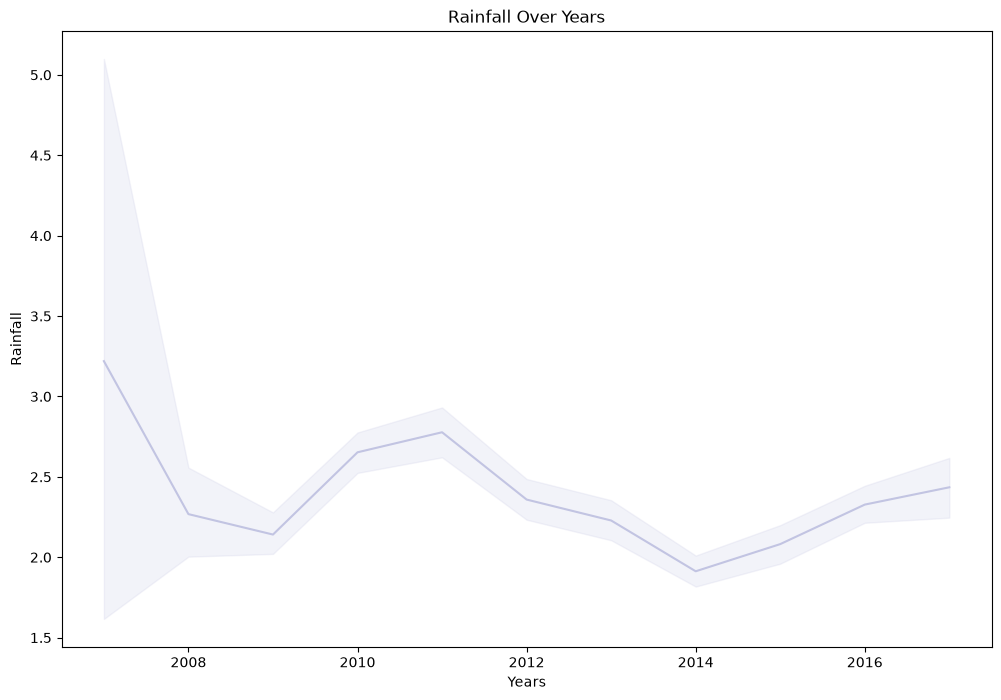

In [60]:
# Plot rainfall over years
plt.figure(figsize=(12, 8))

Time_series = sns.lineplot(
    x=df['Date'].dt.year,
    y="Rainfall",
    data=df,
    color="#C2C4E2"
)

# Add title and axis labels
Time_series.set_title("Rainfall Over Years")
Time_series.set_ylabel("Rainfall")
Time_series.set_xlabel("Years")

plt.show()

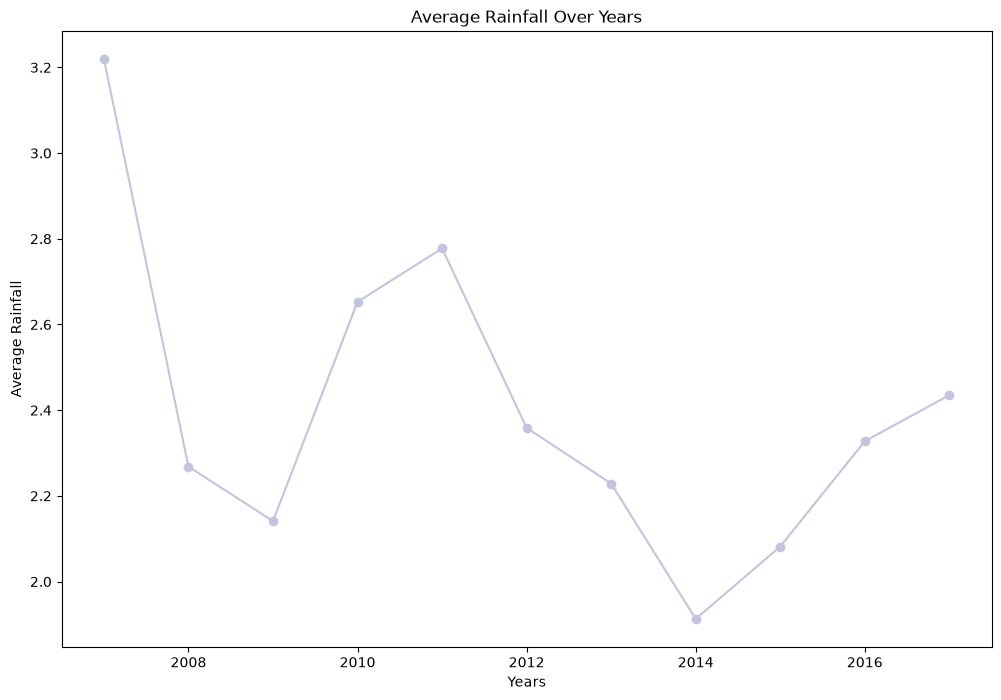

In [61]:
# Calculate average rainfall for each year
yearly_rainfall = df.groupby(
    df['Date'].dt.year
)['Rainfall'].mean()

# Plot yearly average rainfall
yearly_rainfall.plot(
    figsize=(12, 8),
    color="#C2C4E2",
    marker='o'
)

plt.title("Average Rainfall Over Years")
plt.xlabel("Years")
plt.ylabel("Average Rainfall")
plt.show()

/var/folders/lf/0p15d9fx0jjgnppgskwzkqz00000gn/T/ipykernel_35816/2497257351.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  Days_of_week = sns.barplot(
/var/folders/lf/0p15d9fx0jjgnppgskwzkqz00000gn/T/ipykernel_35816/2497257351.py:6: UserWarning: 
The palette list has fewer values (5) than needed (11) and will cycle, which may produce an uninterpretable plot.
  Days_of_week = sns.barplot(


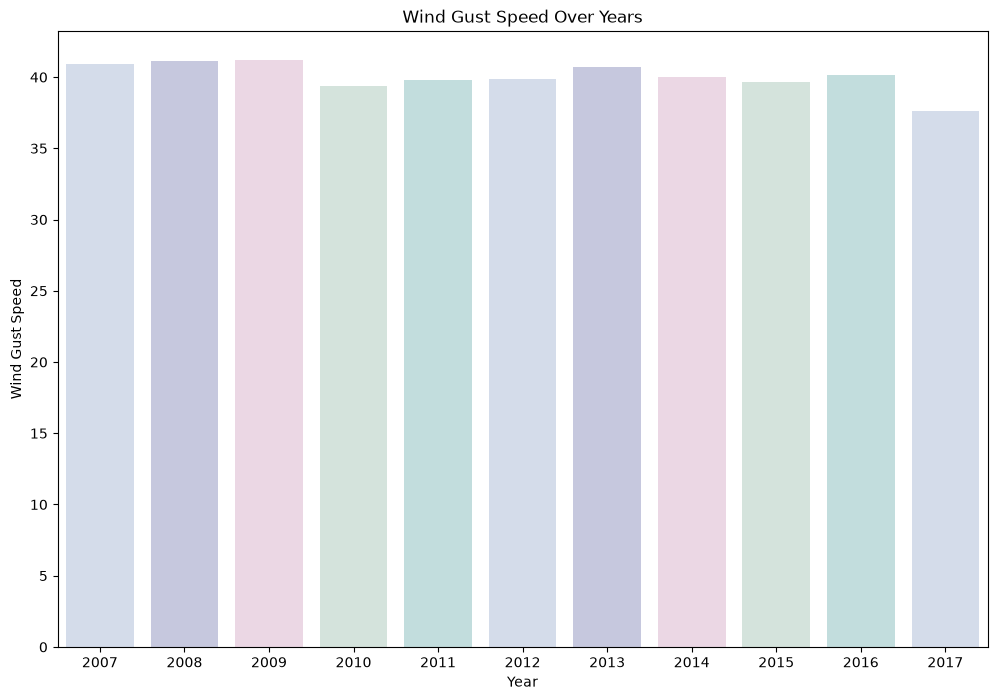

In [62]:
# Evaluate wind gust speed over years
colours = ["#D0DBEE", "#C2C4E2", "#EED4E5", "#D1E6DC", "#BDE2E2"]

plt.figure(figsize=(12, 8))

Days_of_week = sns.barplot(
    x=df['Date'].dt.year,
    y="WindGustSpeed",
    data=df,
    errorbar=None,
    palette=colours
)

# Add title and axis labels
Days_of_week.set_title("Wind Gust Speed Over Years")
Days_of_week.set_ylabel("Wind Gust Speed")
Days_of_week.set_xlabel("Year")

plt.show()

#%% md
<a id="4"></a>
<h2 style='background:#C2C4E2; border:0; color:black'><center>DATA PREPROCESSING</center></h2>

# DATA PREPROCESSING

**Steps involved in Data Preprocessing:**

* Label encoding columns with categorical data
* Perform feature scaling
* Detect outliers
* Drop outliers based on data analysis

In [63]:
# Apply label encoding to categorical columns
label_encoder = LabelEncoder()

for i in object_cols:
    df[i] = label_encoder.fit_transform(df[i])

# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 33 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[us]
 1   Location       145460 non-null  int64         
 2   MinTemp        145460 non-null  float64       
 3   MaxTemp        145460 non-null  float64       
 4   Rainfall       145460 non-null  float64       
 5   Evaporation    145460 non-null  float64       
 6   Sunshine       145460 non-null  float64       
 7   WindGustDir    145460 non-null  int64         
 8   WindGustSpeed  145460 non-null  float64       
 9   WindDir9am     145460 non-null  int64         
 10  WindDir3pm     145460 non-null  int64         
 11  WindSpeed9am   145460 non-null  float64       
 12  WindSpeed3pm   145460 non-null  float64       
 13  Humidity9am    145460 non-null  float64       
 14  Humidity3pm    145460 non-null  float64       
 15  Pressure9am

In [64]:
# Separate input features by dropping target and extra columns
features = df.drop(['RainTomorrow', 'Date', 'day', 'month'], axis=1)

# Separate target column
target = df['RainTomorrow']

# Get feature column names
col_names = list(features.columns)

# Create a StandardScaler object
s_scaler = preprocessing.StandardScaler()

# Scale the input features
features = s_scaler.fit_transform(features)

# Convert scaled array back into a DataFrame
features = pd.DataFrame(features, columns=col_names)

# Display statistical summary
features.describe().T

,count,mean,std,min,25%,50%,75%,max
Location,145460.0,4.376779e-17,1.000003,-1.672228,-0.899139,0.014511,0.857881,1.701250
MinTemp,145460.0,-1.750712e-16,1.000003,-3.250525,-0.705659,-0.030170,0.723865,3.410112
MaxTemp,145460.0,3.001220e-16,1.000003,-3.952405,-0.735852,-0.086898,0.703133,3.510563
Rainfall,145460.0,1.094195e-17,1.000003,-0.275097,-0.275097,-0.275097,-0.203581,43.945571
Evaporation,145460.0,-4.064152e-17,1.000003,-1.629472,-0.371139,-0.119472,0.006361,43.985108
Sunshine,145460.0,9.066185e-17,1.000003,-2.897217,0.076188,0.148710,0.257494,2.360634
WindGustDir,145460.0,3.751525e-17,1.000003,-1.670768,-0.866215,0.139476,0.944029,1.547444
WindGustSpeed,145460.0,1.750712e-16,1.000003,-2.588407,-0.683048,-0.073333,0.460168,7.243246
WindDir9am,145460.0,5.002033e-17,1.000003,-1.614034,-1.004491,0.011413,0.824137,1.636860
WindDir3pm,145460.0,-3.907839e-17,1.000003,-1.688306,-0.844398,-0.000489,0.843420,1.687329


In [65]:
# Find remaining categorical columns
remaining_cols = features.select_dtypes(include=['object']).columns

# Encode remaining categorical columns
for col in remaining_cols:
    features[col] = LabelEncoder().fit_transform(features[col])

In [66]:
# Get feature column names
col_names = list(features.columns)

# Create StandardScaler
s_scaler = preprocessing.StandardScaler()

# Scale features
features = s_scaler.fit_transform(features)

# Convert back to DataFrame
features = pd.DataFrame(features, columns=col_names)

# Display summary
features.describe().T

,count,mean,std,min,25%,50%,75%,max
Location,145460.0,1.250508e-17,1.000003,-1.672228,-0.899139,0.014511,0.857881,1.701250
MinTemp,145460.0,1.250508e-17,1.000003,-3.250525,-0.705659,-0.030170,0.723865,3.410112
MaxTemp,145460.0,-2.501017e-17,1.000003,-3.952405,-0.735852,-0.086898,0.703133,3.510563
Rainfall,145460.0,1.250508e-17,1.000003,-0.275097,-0.275097,-0.275097,-0.203581,43.945571
Evaporation,145460.0,-2.188390e-17,1.000003,-1.629472,-0.371139,-0.119472,0.006361,43.985108
Sunshine,145460.0,1.563135e-17,1.000003,-2.897217,0.076188,0.148710,0.257494,2.360634
WindGustDir,145460.0,2.501017e-17,1.000003,-1.670768,-0.866215,0.139476,0.944029,1.547444
WindGustSpeed,145460.0,-9.378812e-18,1.000003,-2.588407,-0.683048,-0.073333,0.460168,7.243246
WindDir9am,145460.0,2.501017e-17,1.000003,-1.614034,-1.004491,0.011413,0.824137,1.636860
WindDir3pm,145460.0,-1.875762e-17,1.000003,-1.688306,-0.844398,-0.000489,0.843420,1.687329


/var/folders/lf/0p15d9fx0jjgnppgskwzkqz00000gn/T/ipykernel_35816/1084431460.py:10: UserWarning: 
The palette list has fewer values (5) than needed (29) and will cycle, which may produce an uninterpretable plot.
  sns.boxenplot(data=features, palette=colours)


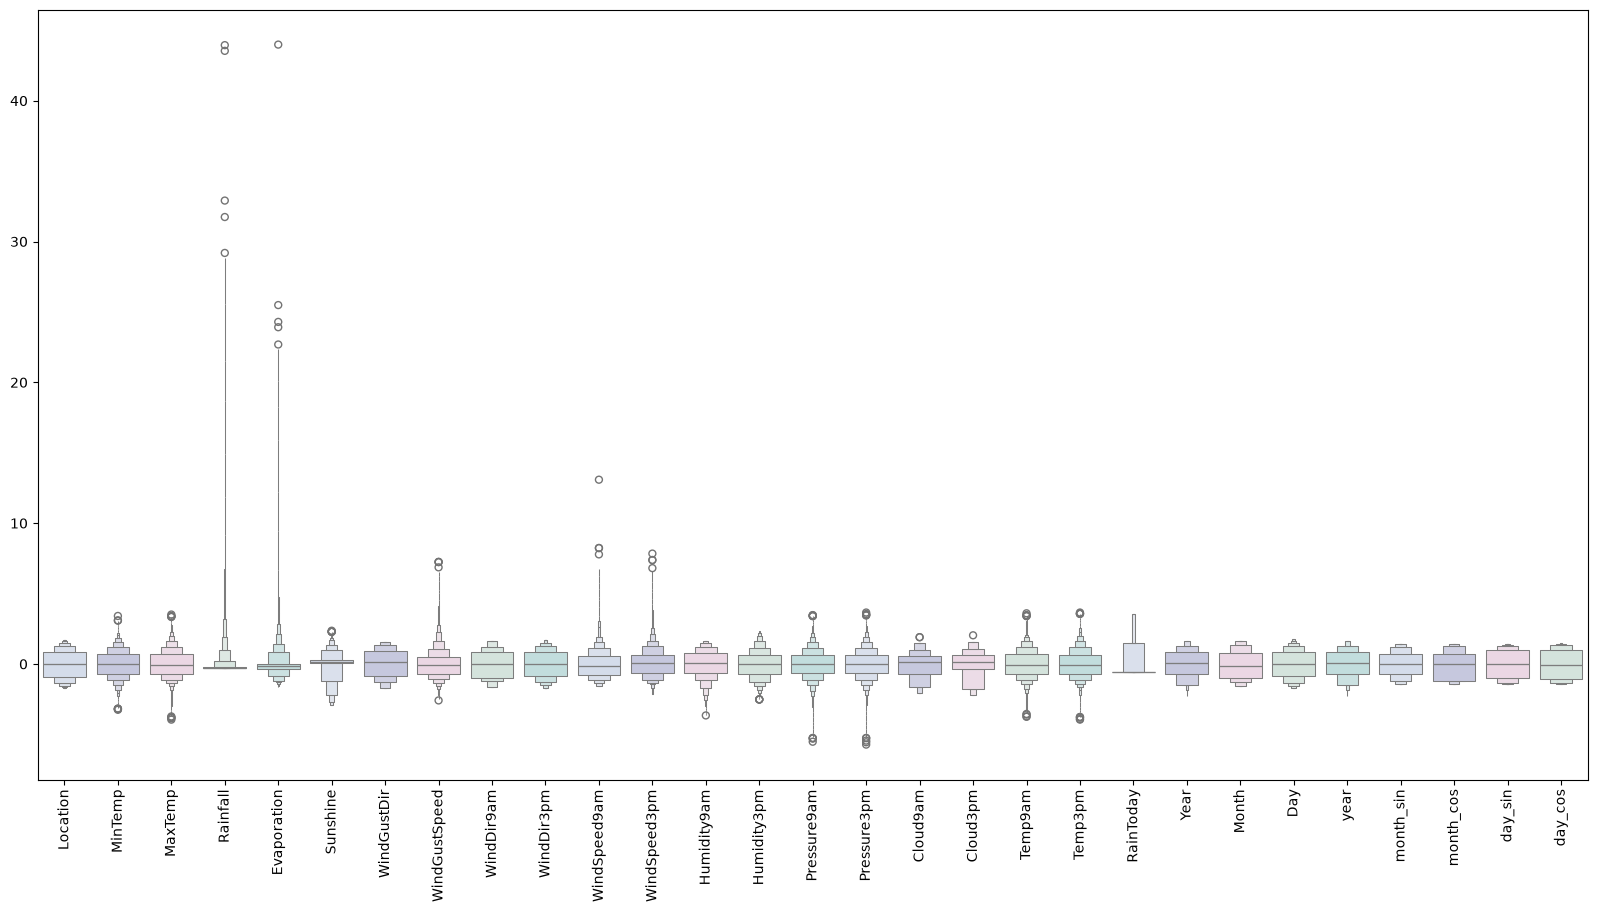

In [67]:
# Detecting outliers using a Boxen Plot

# Define plot colours
colours = ["#D0DBEE", "#C2C4E2", "#EED4E5", "#D1E6DC", "#BDE2E2"]

# Set figure size
plt.figure(figsize=(20, 10))

# Create Boxen Plot
sns.boxenplot(data=features, palette=colours)

# Rotate column names
plt.xticks(rotation=90)

# Display plot
plt.show()

In [68]:
# Add target column to features
features["RainTomorrow"] = target

# Remove outliers using selected thresholds
features = features[(features["MinTemp"] < 2.3) & (features["MinTemp"] > -2.3)]

features = features[(features["MaxTemp"] < 2.3) & (features["MaxTemp"] > -2)]

features = features[features["Rainfall"] < 4.5]
features = features[features["Evaporation"] < 2.8]
features = features[features["Sunshine"] < 2.1]

features = features[(features["WindGustSpeed"] < 4) & (features["WindGustSpeed"] > -4)]

features = features[features["WindSpeed9am"] < 4]
features = features[features["WindSpeed3pm"] < 2.5]

features = features[features["Humidity9am"] > -3]
features = features[features["Humidity3pm"] > -2.2]

features = features[(features["Pressure9am"] < 2) & (features["Pressure9am"] > -2.7)]

features = features[(features["Pressure3pm"] < 2) & (features["Pressure3pm"] > -2.7)]

features = features[features["Cloud9am"] < 1.8]
features = features[features["Cloud3pm"] < 2]

features = features[(features["Temp9am"] < 2.3) & (features["Temp9am"] > -2)]

features = features[(features["Temp3pm"] < 2.3) & (features["Temp3pm"] > -2)]

# Check the remaining dataset shape
features.shape

(127536, 30)

In [69]:
# Separate input features and target
target = features["RainTomorrow"]
features = features.drop("RainTomorrow", axis=1)

# Check final shapes
print("Features shape:", features.shape)
print("Target shape:", target.shape)

Features shape: (127536, 29)
Target shape: (127536,)


/var/folders/lf/0p15d9fx0jjgnppgskwzkqz00000gn/T/ipykernel_35816/143061666.py:6: UserWarning: 
The palette list has fewer values (5) than needed (29) and will cycle, which may produce an uninterpretable plot.
  sns.boxenplot(data=features, palette=colours)


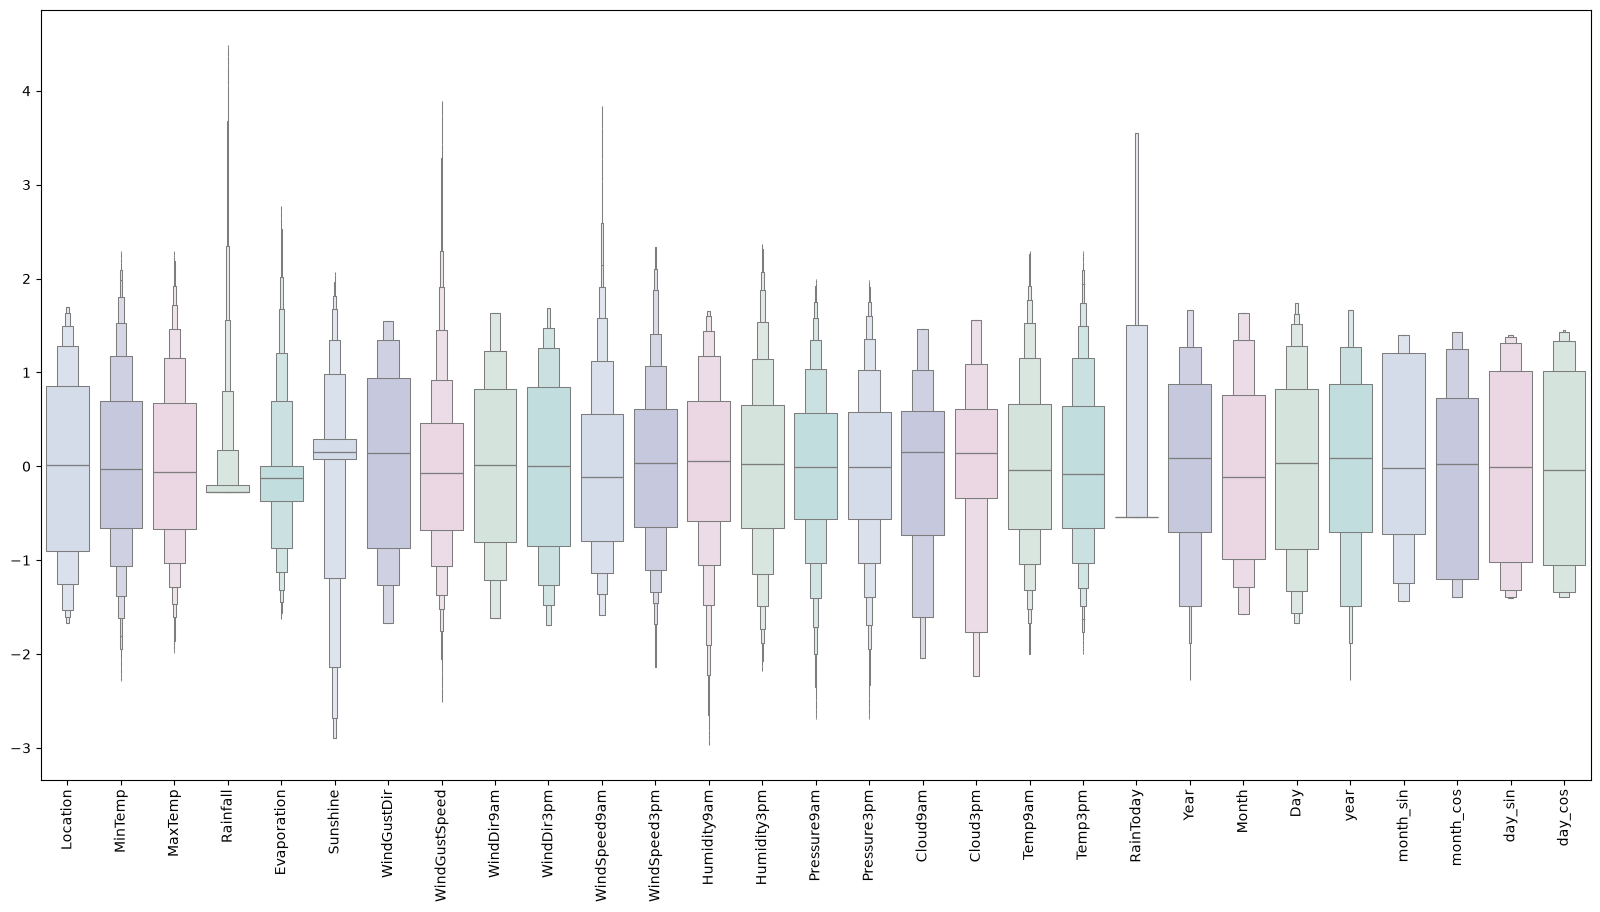

In [70]:
# Visualize scaled features after removing outliers

plt.figure(figsize=(20, 10))

# Create Boxen Plot
sns.boxenplot(data=features, palette=colours)

# Rotate feature names
plt.xticks(rotation=90)

# Display plot
plt.show()

#%% md
<a id="5"></a>
<h2 style='background:#C2C4E2; border:0; color:black'><center>MODEL BUILDING</center></h2>

# MODEL BUILDING

**In this project, we build an Artificial Neural Network (ANN).**

**Following steps are involved in model building:**

* Assigning X and y as input features and target labels
* Splitting training and testing datasets
* Initializing the neural network
* Defining the neural network by adding layers
* Compiling the neural network
* Training the neural network

In [71]:
target = features["RainTomorrow"]
features = features.drop("RainTomorrow", axis=1)

KeyError: 'RainTomorrow'

In [73]:
# Assign input features and target
X = features
y = target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check dataset shape
print("X shape:", X.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X shape: (127536, 29)
X_train shape: (102028, 29)
X_test shape: (25508, 29)
y_train shape: (102028,)
y_test shape: (25508,)


In [74]:
# Early stopping
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',          # Monitor validation loss
    min_delta=0.001,             # Minimum improvement
    patience=20,                 # Wait for 20 epochs
    restore_best_weights=True   # Restore best model weights
)

# Initialize the neural network
model = Sequential()

# Add input and hidden layers
model.add(Dense(units=32, kernel_initializer='uniform',
                activation='relu', input_dim=X_train.shape[1]))

model.add(Dense(units=32, kernel_initializer='uniform', activation='relu'))

model.add(Dense(units=16, kernel_initializer='uniform', activation='relu'))

model.add(Dropout(0.25))         # Drop 25% of neurons

model.add(Dense(units=8, kernel_initializer='uniform', activation='relu'))

model.add(Dropout(0.5))          # Drop 50% of neurons

# Output layer
model.add(Dense(units=1, kernel_initializer='uniform', activation='sigmoid'))

# Compile the ANN
opt = Adam(learning_rate=0.00009)

model.compile(
    optimizer=opt,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the ANN
history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=150,
    callbacks=[early_stopping],
    validation_split=0.2
)

/Users/yadavraunak50gmail.com/myenv/Deep Learning/.venv/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 4s 875us/step - accuracy: 0.7627 - loss: 0.5187 - val_accuracy: 0.7611 - val_loss: 0.4358
Epoch 2/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 2s 827us/step - accuracy: 0.7851 - loss: 0.4583 - val_accuracy: 0.8129 - val_loss: 0.4258
Epoch 3/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7858 - loss: 0.4519 - val_accuracy: 0.8141 - val_loss: 0.4165
Epoch 4/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 2s 852us/step - accuracy: 0.7892 - loss: 0.4424 - val_accuracy: 0.8152 - val_loss: 0.4086
Epoch 5/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 2s 884us/step - accuracy: 0.7978 - loss: 0.4364 - val_accuracy: 0.8177 - val_loss: 0.4013
Epoch 6/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 2s 905us/step - accuracy: 0.8035 - loss: 0.4338 - val_accuracy: 0.8185 - val_loss: 0.3957
Epoch 7/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 2s 839us/step - accuracy: 0.8027 - loss: 0.4284 - val_accuracy: 0.8193 - val_loss: 0.3909
Epoch 8/150
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 2s 830us/step - accuracy: 0.

Plotting training and validation loss over epochs

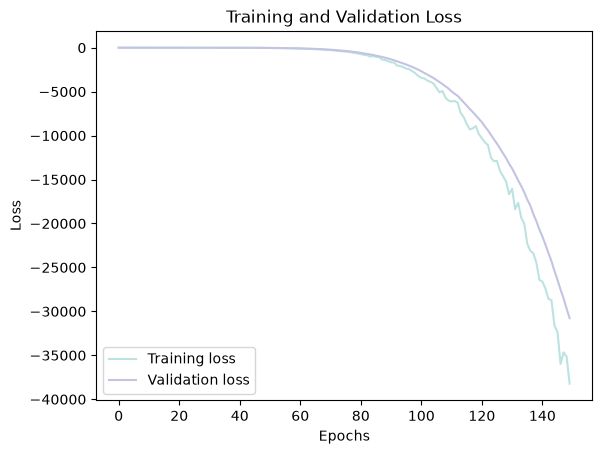

In [75]:
# Convert training history into a DataFrame
history_df = pd.DataFrame(history.history)

# Plot training and validation loss
plt.plot(history_df['loss'], color="#BDE2E2", label='Training loss')
plt.plot(history_df['val_loss'], color="#C2C4E2", label='Validation loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc="best")
plt.show()

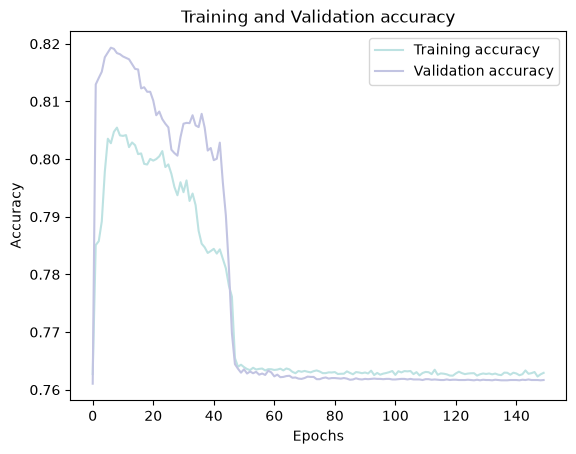

In [ ]:
# Convert training history into a DataFrame
history_df = pd.DataFrame(history.history)

# Plot training and validation loss
plt.plot(history_df.loc[:, ['accuracy']], "#BDE2E2", label='Training accuracy')
plt.plot(history_df.loc[:, ['val_accuracy']], "#C2C4E2", label='Validation accuracy')

plt.title('Training and Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

#%% md
<a id="6"></a>
<h2 style='background:#C2C4E2; border:0; color:black'><center>CONCLUSION</center></h2>

# CONCLUSION

**Evaluating the model with:**

* Testing on the test set
* Evaluating the confusion matrix
* Evaluating the classification report

In [80]:
# Predicting the test set results
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5)

798/798 ━━━━━━━━━━━━━━━━━━━━ 0s 383us/step


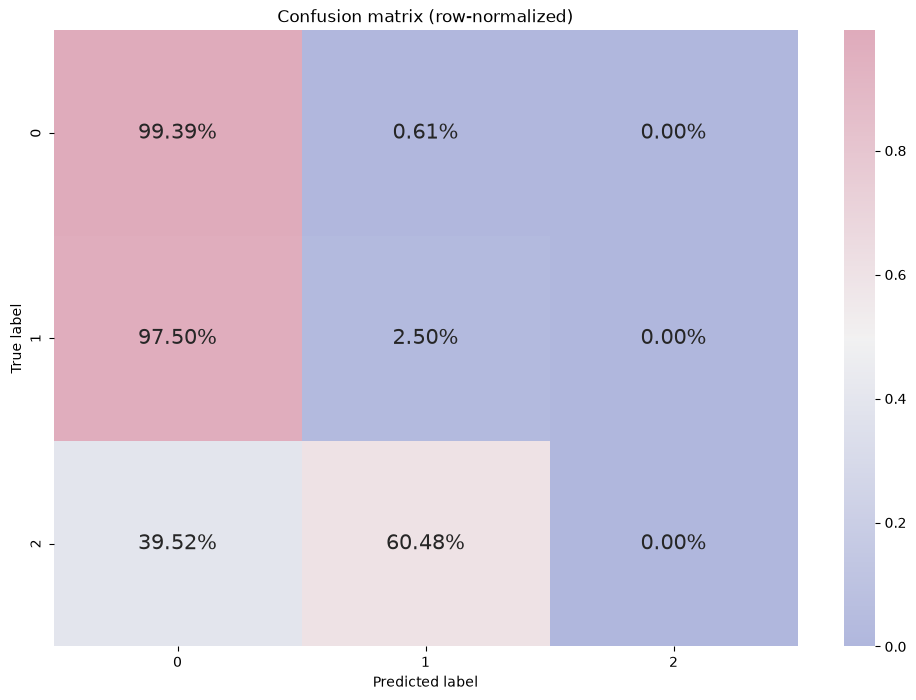

In [83]:
cmap1 = sns.diverging_palette(260, -10, s=50, l=75, n=5, as_cmap=True)

cf_matrix = confusion_matrix(y_test, y_pred)
cf_norm = cf_matrix / cf_matrix.sum(axis=1, keepdims=True)  # per-true-class

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(cf_norm, cmap=cmap1, annot=True, fmt='.2%',
            annot_kws={'size': 15}, ax=ax)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion matrix (row-normalized)')
plt.show()

In [84]:

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.99      0.87     19450
           1       0.23      0.03      0.05      5476
           2       0.00      0.00      0.00       582

    accuracy                           0.76     25508
   macro avg       0.33      0.34      0.31     25508
weighted avg       0.64      0.76      0.67     25508



/Users/yadavraunak50gmail.com/myenv/Deep Learning/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yadavraunak50gmail.com/myenv/Deep Learning/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yadavraunak50gmail.com/myenv/Deep Learning/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co